# Libraries Import

In [1]:
# Customer Churn Prediction
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


# Dataset Load

In [4]:
# Step 2: Load Customer Churn Dataset

url = "https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Step 3: Understand the Dataset

print("Dataset Shape (Rows, Columns):")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape (Rows, Columns):
(7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecu

# Data Cleaning

In [6]:
# Step 4: Data Cleaning

# Check dataset size
print("Original Dataset Shape:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Remove customer ID column if it exists
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Clean TotalCharges column if it exists
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

# Check missing values
print("\nMissing Values Before Handling:")
print(df.isnull().sum())

# Handle missing values
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

print("\nCleaned Dataset Shape:", df.shape)

display(df.head())

Original Dataset Shape: (7043, 21)

Missing Values Before Handling:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing Values After Cleaning:
0

Cleaned Dataset Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Customer Churn Visualization

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


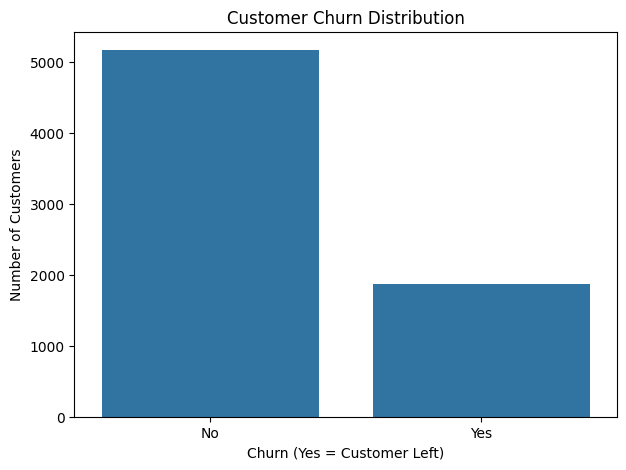

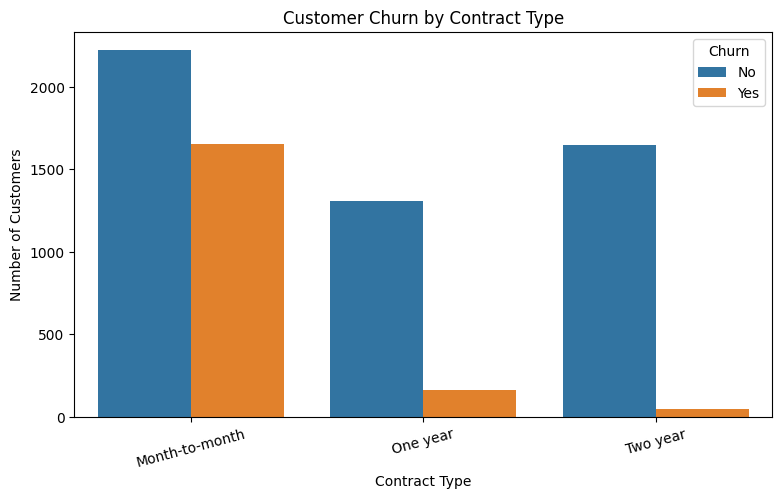

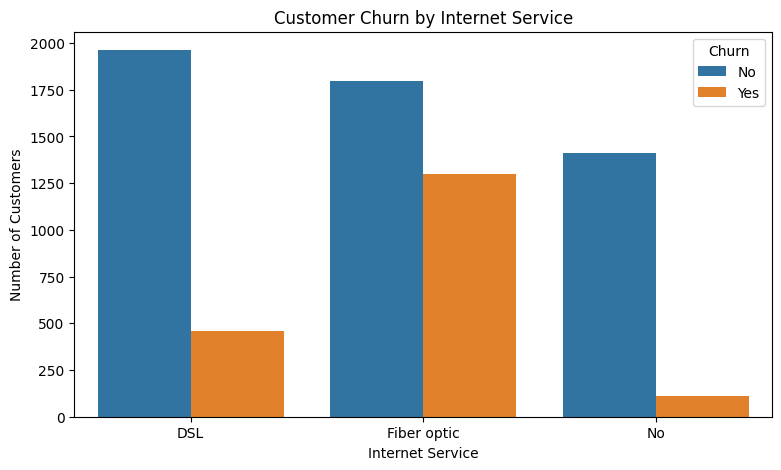

In [7]:
# Step 5: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# Check churn distribution
print("Churn Distribution:")
print(df["Churn"].value_counts())

# Plot 1: Churn Count
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (Yes = Customer Left)")
plt.ylabel("Number of Customers")
plt.show()

# Plot 2: Churn by Contract Type
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

# Plot 3: Churn by Internet Service
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

# Feature Encoding & Train-Test Split

In [8]:
# Step 6: Prepare Data for Machine Learning

# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"Yes": 1, "No": 0})

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features converted into numerical format!")
print("Total Features:", X.shape[1])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features converted into numerical format!
Total Features: 30

Training Data Shape: (5634, 30)
Testing Data Shape: (1409, 30)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


# Train Both Models

In [9]:
# Step 7: Train Machine Learning Models

# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression model trained successfully!
Random Forest model trained successfully!


# Evaluate Both Models

In [10]:
# Step 8: Model Evaluation

# Predictions
log_pred = log_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Prediction probabilities for ROC-AUC
log_prob = log_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluation function
def evaluate_model(name, y_true, y_pred, y_prob):
    print(f"\n{'=' * 40}")
    print(name)
    print('=' * 40)

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1-Score :", round(f1_score(y_true, y_pred, zero_division=0), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_true, y_prob), 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

# Evaluate Logistic Regression
evaluate_model(
    "Logistic Regression",
    y_test,
    log_pred,
    log_prob
)

# Evaluate Random Forest
evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)


Logistic Regression
Accuracy : 0.8041
Precision: 0.6541
Recall   : 0.5561
F1-Score : 0.6012
ROC-AUC  : 0.8425

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409


Random Forest
Accuracy : 0.7878
Precision: 0.6271
Recall   : 0.4947
F1-Score : 0.5531
ROC-AUC  : 0.8209

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



# Confusion Matrix aur Model Comparison Chart

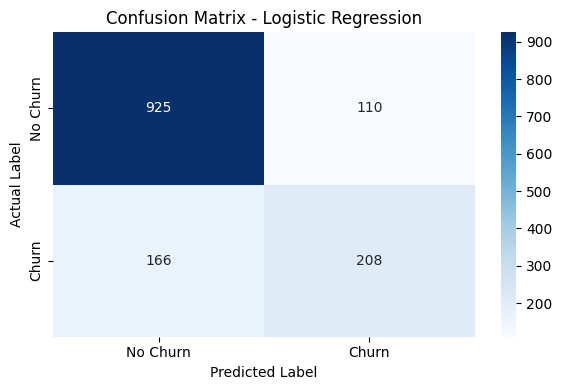

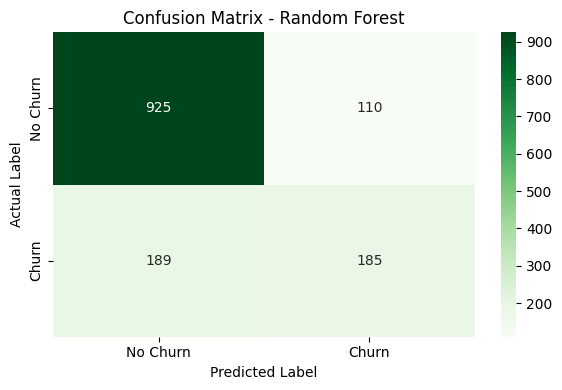

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8041,0.6541,0.5561,0.6012,0.8425
1,Random Forest,0.7878,0.6271,0.4947,0.5531,0.8209


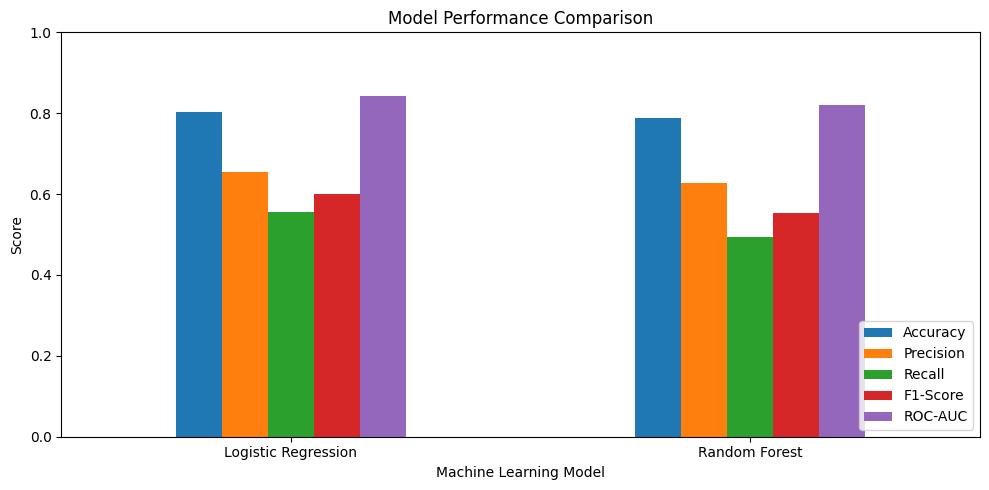

In [11]:
# Step 9: Confusion Matrix and Model Comparison

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Confusion Matrix for Logistic Regression
cm_log = confusion_matrix(y_test, log_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


# Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


# Compare Model Performance
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, log_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, log_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, log_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Important Features Identify Karo

Top 10 Important Features - Logistic Regression


,Feature,Coefficient,Absolute_Importance
25,Contract_Two year,-1.339408,1.339408
10,InternetService_Fiber optic,0.753713,0.753713
24,Contract_One year,-0.688947,0.688947
13,OnlineSecurity_Yes,-0.433997,0.433997
7,PhoneService_Yes,-0.429248,0.429248
28,PaymentMethod_Electronic check,0.392847,0.392847
19,TechSupport_Yes,-0.385966,0.385966
26,PaperlessBilling_Yes,0.377905,0.377905
9,MultipleLines_Yes,0.278051,0.278051
6,Dependents_Yes,-0.224131,0.224131


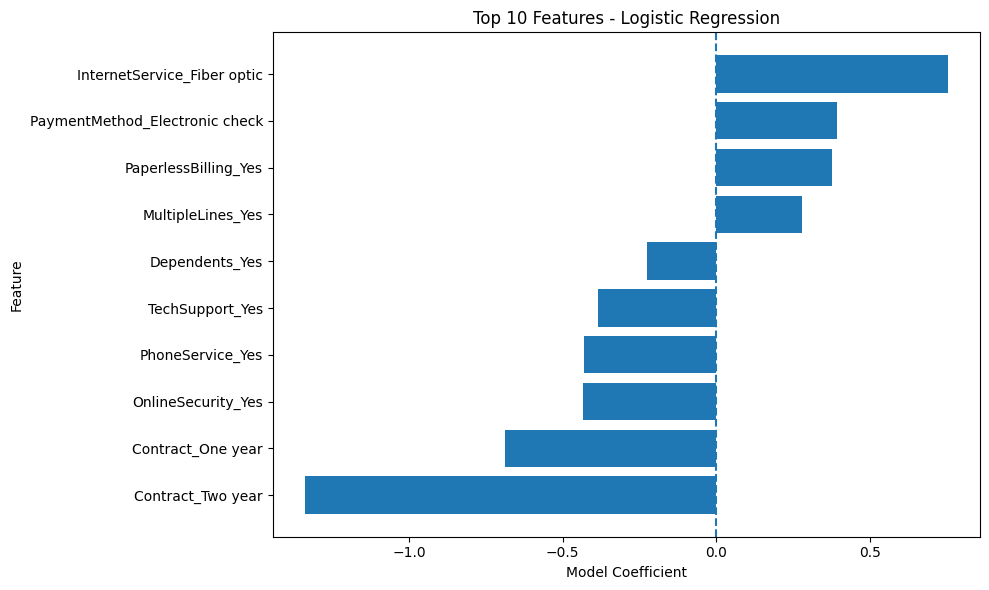

In [12]:
# Step 10: Feature Importance Analysis

# Logistic Regression: Top important features
log_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_model.coef_[0]
})

log_importance["Absolute_Importance"] = (
    log_importance["Coefficient"].abs()
)

log_importance = log_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

print("Top 10 Important Features - Logistic Regression")
display(log_importance.head(10))

# Visualize important features
top_features = log_importance.head(10).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.axvline(x=0, linestyle="--")
plt.title("Top 10 Features - Logistic Regression")
plt.xlabel("Model Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Predict Customer Churn

In [13]:
# Step 11: Customer Churn Prediction

# Select the better-performing model
best_model = log_model

# Predict churn for test customers
predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)[:, 1]

# Create prediction results
results = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": predictions,
    "Churn_Probability": probabilities
})

# Convert numeric predictions into readable labels
results["Actual_Churn"] = results["Actual_Churn"].map({
    0: "No",
    1: "Yes"
})

results["Predicted_Churn"] = results["Predicted_Churn"].map({
    0: "No",
    1: "Yes"
})

results["Churn_Probability"] = (
    results["Churn_Probability"] * 100
).round(2)

print("Customer Churn Predictions")
display(results.head(10))

print("\nTotal customers evaluated:", len(results))
print(
    "Customers predicted to churn:",
    (predictions == 1).sum()
)

Customer Churn Predictions


,Actual_Churn,Predicted_Churn,Churn_Probability
0,No,No,4.56
1,No,Yes,68.30
2,No,No,6.31
3,No,No,39.10
4,No,No,2.05
5,No,Yes,60.09
6,No,No,44.13
7,No,No,12.66
8,No,No,0.27
9,Yes,No,39.70



Total customers evaluated: 1409
Customers predicted to churn: 318


# Business Insights Generate

In [14]:
# Step 12: Business Insights

total_customers = len(results)
predicted_churners = (predictions == 1).sum()
predicted_non_churners = (predictions == 0).sum()

churn_percentage = (
    predicted_churners / total_customers
) * 100

print("CUSTOMER CHURN BUSINESS INSIGHTS")
print("-" * 40)

print("Total Test Customers:", total_customers)

print(
    "Predicted Churn Customers:",
    predicted_churners
)

print(
    "Predicted Non-Churn Customers:",
    predicted_non_churners
)

print(
    "Predicted Churn Percentage:",
    round(churn_percentage, 2), "%"
)

print("\nBUSINESS RECOMMENDATIONS")

print("1. Identify high-risk customers early.")
print("2. Offer suitable retention plans to at-risk customers.")
print("3. Review contract options and customer complaints.")
print("4. Improve customer service and support.")
print("5. Monitor churn predictions regularly.")

CUSTOMER CHURN BUSINESS INSIGHTS
----------------------------------------
Total Test Customers: 1409
Predicted Churn Customers: 318
Predicted Non-Churn Customers: 1091
Predicted Churn Percentage: 22.57 %

BUSINESS RECOMMENDATIONS
1. Identify high-risk customers early.
2. Offer suitable retention plans to at-risk customers.
3. Review contract options and customer complaints.
4. Improve customer service and support.
5. Monitor churn predictions regularly.
